# 🚲 Parquet contra CSV con los viajes de Ecobici

Parquet es un formato que guarda los datos por columnas, comprimidos y con su tipo. En esta notebook lo comparamos con el CSV usando un archivo real y grande: los más de 3 millones de viajes en Ecobici de 2025, que publica la Ciudad de Buenos Aires en [Buenos Aires Data](https://data.buenosaires.gob.ar/dataset/bicicletas-publicas). También hay una [versión en R](https://colab.research.google.com/github/jumafernandez/modelado-gestion-datos-untref/blob/main/codigo/r_parquet_vs_csv.ipynb) de la misma notebook.

Medimos cuatro cosas:

1. Cuánto pesa cada archivo.
2. Cuánto tarda en cargarse completo.
3. Cuánto tarda en leer solo dos columnas.
4. Cuánto tarda DuckDB en responder una consulta sobre cada uno.

> Los tiempos dependen de la máquina de Colab que toque en cada sesión. Lo que importa es la diferencia entre los dos formatos.

## 📥 Los datos

Bajamos el archivo de 2025: un ZIP de unos 200 MB que adentro tiene un CSV de más de 800 MB. Para que la descarga sea más rápida usamos `aria2c`, que baja el archivo en varias partes a la vez.

In [1]:
!apt-get install -y -qq aria2 > /dev/null
!aria2c -x 16 -s 16 -q --allow-overwrite=true -o recorridos-2025.zip https://cdn.buenosaires.gob.ar/datosabiertos/datasets/transporte-y-obras-publicas/bicicletas-publicas/recorridos-realizados-2025.zip
!unzip -o -q recorridos-2025.zip
!ls -l --block-size=MB Trips.csv

-rw-r--r-- 1 root root 833MB Jan 13  2026 Trips.csv


## 📄 Leer el CSV

Leemos el CSV con pandas y medimos cuánto tarda.

In [2]:
import time
import pandas as pd

inicio = time.perf_counter()
viajes = pd.read_csv("Trips.csv")
carga_csv = time.perf_counter() - inicio

print(f"{len(viajes):,} viajes leídos en {carga_csv:.1f} segundos")
viajes.head()

3,156,182 viajes leídos en 22.7 segundos


,Id_recorrido,duracion_recorrido,fecha_origen_recorrido,id_estacion_origen,nombre_estacion_origen,direccion_estacion_origen,long_estacion_origen,lat_estacion_origen,fecha_destino_recorrido,id_estacion_destino,nombre_estacion_destino,direccion_estacion_destino,long_estacion_destino,lat_estacion_destino,id_usuario,modelo_bicicleta,género
0,27699090BAEcobici,800,2025-10-15 11:12:52,146BAEcobici,146 - Hospital Francés,"3024 Calvo, Carlos",-58.407842,-34.622112,2025-10-15 11:26:12,17BAEcobici,017 - Plaza Almagro,"441 Bulnes & Peron, Juan Domingo, Tte. General",-58.418731,-34.606410,1177390BAEcobici,ICONIC,FEMALE
1,24622664BAEcobici,571,2025-01-10 08:48:58,70BAEcobici,070 - ARAOZ,1413 Araoz & Gorriti CABA,-58.426060,-34.592686,2025-01-10 08:58:29,74BAEcobici,074 - INSTITUTO LELOIR,Juana De Ibarbourou & Av Patricias Argentinas,-58.434540,-34.604390,357363BAEcobici,ICONIC,OTHER
2,24621373BAEcobici,348,2025-01-10 07:11:15,135BAEcobici,135 - MARCELO T. DE ALVEAR,Esmeralda & Paraguay,-58.378363,-34.597642,2025-01-10 07:17:03,130BAEcobici,130 - RETIRO II,Av. Dr. José María Ramos Mejía 1350,-58.374364,-34.591738,693254BAEcobici,ICONIC,MALE
3,27815450BAEcobici,343,2025-10-23 09:03:21,471BAEcobici,173 - EL LIBERTADOR,Av. San Martín 6220,-58.503309,-34.594729,2025-10-23 09:09:04,241BAEcobici,348 - Villa del Parque,"Gutierrez, Ricardo 3105",-58.494123,-34.600874,459726BAEcobici,ICONIC,MALE
4,28272276BAEcobici,931,2025-11-26 00:25:37,466BAEcobici,333 - PARQUE DE LA ESTACIÓN,Dr. Tomás Manuel de Anchorena 170,-58.411840,-34.608096,2025-11-26 00:41:08,527BAEcobici,068 - AV. CORDOBA,Av. Cordoba 5403,-58.438386,-34.588727,1153980BAEcobici,ICONIC,MALE


### Los tipos se pierden

Un CSV es texto: no guarda qué tipo de dato tiene cada columna, y pandas lo tiene que adivinar. Acá adivina mal dos cosas:

- Las fechas quedan como texto (`object`).
- La duración del viaje, en segundos, también queda como texto. Las duraciones de 1.000 segundos o más vienen escritas con una coma como separador de miles (`1,016`), así que la columna no se puede leer como número. Es un problema real de los datos publicados.

In [3]:
print(viajes[["duracion_recorrido", "fecha_origen_recorrido"]].dtypes)

viajes[viajes["duracion_recorrido"].str.contains(",")]["duracion_recorrido"].head()

duracion_recorrido        object
fecha_origen_recorrido    object
dtype: object


,duracion_recorrido
5,"3,108"
6,"1,465"
8,"1,570"
11,"1,476"
12,"1,508"


Corregimos los tipos y guardamos la tabla en Parquet. Parquet guarda cada columna con su tipo, así que al leerlo de nuevo no hay que volver a corregirlos.

In [4]:
viajes["duracion_recorrido"] = pd.to_numeric(viajes["duracion_recorrido"].str.replace(",", ""))
viajes["fecha_origen_recorrido"] = pd.to_datetime(viajes["fecha_origen_recorrido"])
viajes["fecha_destino_recorrido"] = pd.to_datetime(viajes["fecha_destino_recorrido"])

viajes.to_parquet("viajes.parquet", index=False)

pd.read_parquet("viajes.parquet", columns=["duracion_recorrido", "fecha_origen_recorrido"]).dtypes

,0
duracion_recorrido,int64
fecha_origen_recorrido,datetime64[ns]


## ⚖️ La comparación

### 1. El tamaño

Parquet comprime cada columna por separado, y una columna tiene datos muy parecidos entre sí, como la misma estación o el mismo modelo de bicicleta repetidos muchas veces. Por eso comprime mucho mejor que el texto del CSV.

In [5]:
import os

tamanio_csv = os.path.getsize("Trips.csv") / 1e6
tamanio_parquet = os.path.getsize("viajes.parquet") / 1e6

print(f"CSV: {tamanio_csv:.0f} MB")
print(f"Parquet: {tamanio_parquet:.0f} MB")

CSV: 832 MB
Parquet: 142 MB


### 2. Cargar todo

Ya medimos cuánto tarda el CSV. Ahora, el Parquet.

In [6]:
inicio = time.perf_counter()
pd.read_parquet("viajes.parquet")
carga_parquet = time.perf_counter() - inicio

print(f"CSV: {carga_csv:.1f} segundos")
print(f"Parquet: {carga_parquet:.1f} segundos")

CSV: 22.7 segundos
Parquet: 6.3 segundos


### 3. Leer solo dos columnas

Muchas veces no hacen falta todas las columnas. El CSV guarda los datos fila por fila, así que para sacar dos columnas igual tiene que recorrer el archivo completo. Parquet los guarda columna por columna y lee solo las que se le piden.

In [7]:
COLUMNAS = ["fecha_origen_recorrido", "género"]

inicio = time.perf_counter()
pd.read_csv("Trips.csv", usecols=COLUMNAS)
columnas_csv = time.perf_counter() - inicio

inicio = time.perf_counter()
pd.read_parquet("viajes.parquet", columns=COLUMNAS)
columnas_parquet = time.perf_counter() - inicio

print(f"CSV: {columnas_csv:.1f} segundos")
print(f"Parquet: {columnas_parquet:.2f} segundos")

CSV: 10.0 segundos
Parquet: 0.37 segundos


### 4. Una consulta con DuckDB

DuckDB consulta los archivos directamente, sin cargarlos antes en pandas. Contamos los viajes de cada hora del día, primero sobre el CSV y después sobre el Parquet.

In [8]:
import duckdb

def viajes_por_hora(archivo):
    return duckdb.sql(f"""
        SELECT hour(fecha_origen_recorrido) AS hora, COUNT(*) AS viajes
        FROM '{archivo}'
        GROUP BY hora
        ORDER BY hora
    """).df()

inicio = time.perf_counter()
viajes_por_hora("Trips.csv")
consulta_csv = time.perf_counter() - inicio

inicio = time.perf_counter()
por_hora = viajes_por_hora("viajes.parquet")
consulta_parquet = time.perf_counter() - inicio

print(f"CSV: {consulta_csv:.2f} segundos")
print(f"Parquet: {consulta_parquet:.2f} segundos")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CSV: 3.94 segundos
Parquet: 0.11 segundos


## 📊 Los resultados

Las cuatro comparaciones juntas. Arriba de cada gráfico, cuántas veces mejor le fue a Parquet.

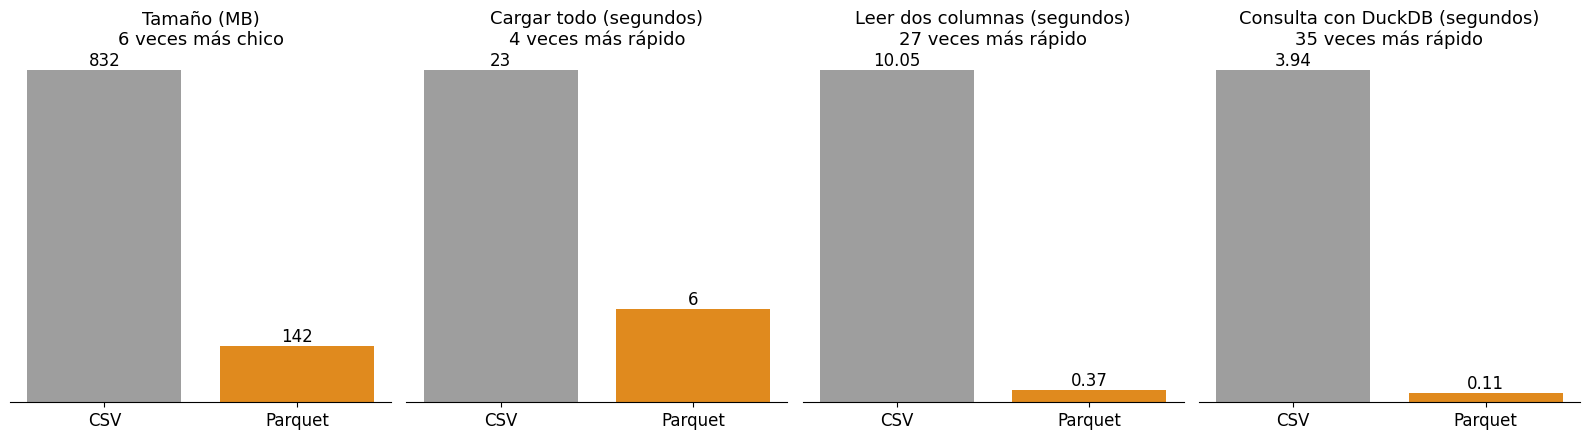

In [9]:
import matplotlib.pyplot as plt

comparaciones = [
    ("Tamaño (MB)", tamanio_csv, tamanio_parquet, "más chico"),
    ("Cargar todo (segundos)", carga_csv, carga_parquet, "más rápido"),
    ("Leer dos columnas (segundos)", columnas_csv, columnas_parquet, "más rápido"),
    ("Consulta con DuckDB (segundos)", consulta_csv, consulta_parquet, "más rápido"),
]

fig, ejes = plt.subplots(1, 4, figsize=(16, 4.5))
for eje, (titulo, csv, parquet, mejor) in zip(ejes, comparaciones):
    barras = eje.bar(["CSV", "Parquet"], [csv, parquet], color=["#9e9e9e", "#e08a1e"])
    eje.bar_label(barras, fmt="%.2f" if parquet < 1 else "%.0f", fontsize=12)
    eje.set_title(f"{titulo}\n{csv / parquet:.0f} veces {mejor}", fontsize=13)
    eje.tick_params(axis="x", labelsize=12)
    eje.set_yticks([])
    eje.spines[["top", "right", "left"]].set_visible(False)

plt.tight_layout()
plt.show()

## 🕐 Y de paso, ¿a qué hora se usa Ecobici?

El resultado de la consulta de DuckDB, en un gráfico.

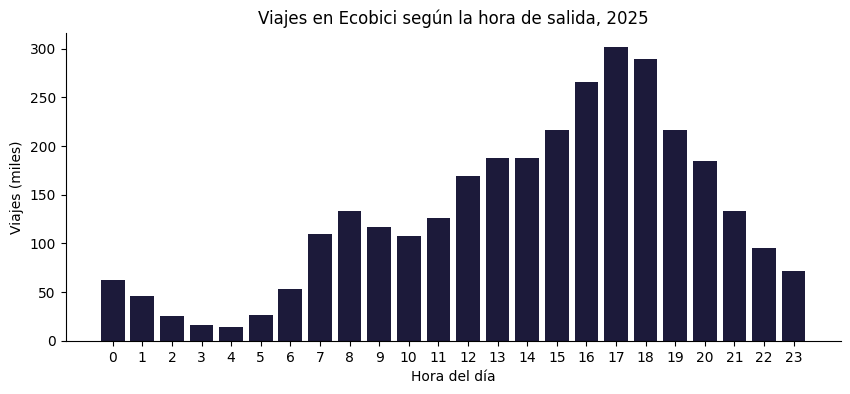

In [10]:
plt.figure(figsize=(10, 4))
plt.bar(por_hora["hora"], por_hora["viajes"] / 1000, color="#1c1a3a")
plt.title("Viajes en Ecobici según la hora de salida, 2025")
plt.xlabel("Hora del día")
plt.ylabel("Viajes (miles)")
plt.xticks(range(24))
plt.gca().spines[["top", "right"]].set_visible(False)
plt.show()

## 🧾 Para llevarse

- Parquet ocupa varias veces menos que el CSV y conserva el tipo de cada columna.
- Para cargar todo, Parquet es más rápido. Hay lectores de CSV más rápidos que el de pandas, pero cualquier lector de CSV tiene que leer el texto completo.
- La diferencia más grande aparece al leer pocas columnas: Parquet lee solo esas, y el CSV tiene que recorrer todo el archivo.
- DuckDB consulta los dos formatos sin cargarlos en memoria, y sobre Parquet responde mucho más rápido.

Por eso Parquet es el formato de los data lakes y de los lakehouses: los datos quedan en archivos abiertos que cualquier herramienta puede leer, y se consultan rápido.